# Exploring `final.csv`
A first look at the data: target distribution, how danger evolves over a season, and how the weather features relate to the danger level.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("data/final.csv", parse_dates=["date"])
data["month"] = data["date"].dt.month

# colors: danger levels 1-4 as one ordered blue ramp (light = low, dark = high)
LEVEL_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#1c5cab", 4: "#0d366b"}
LEVEL_NAMES = {1: "1 low", 2: "2 moderate", 3: "3 considerable", 4: "4 high"}
BLUE, ORANGE = "#2a78d6", "#eb6834"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 11,
})

print(data.shape)
data.head()

(9729, 28)


,date,season,region,region_name,danger_max,danger_above,danger_below,elev_limit,danger_am,danger_pm,...,wind_gust_max,rel_humidity_mean,pressure_mean,sunshine_sum,snow_depth_cm,precip_sum_mm,wind_dir_deg,days_before,station_name,month
0,2019-11-16,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,treeline,2,2,...,33.856725,73.789474,775.711771,0.000000,33.055203,6.151518,115.0,1,Valluga,11
1,2019-11-17,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,2000,2,2,...,17.480702,83.351121,779.665096,3.404094,43.642186,7.139951,155.0,1,Valluga,11
2,2019-11-18,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,2200,2,2,...,17.865497,87.455166,780.461596,0.000000,57.721002,11.023889,82.0,1,Valluga,11
3,2019-11-19,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,2200,2,2,...,15.638596,85.141326,779.968669,3.314620,54.676675,2.768592,128.0,1,Valluga,11
4,2019-11-20,2019/20,AT-07-07,Lechtaler Alpen West,2,2,1.0,2200,2,2,...,12.977778,81.423733,786.581303,1.429240,49.627798,0.000000,120.0,1,Valluga,11


## Missing values

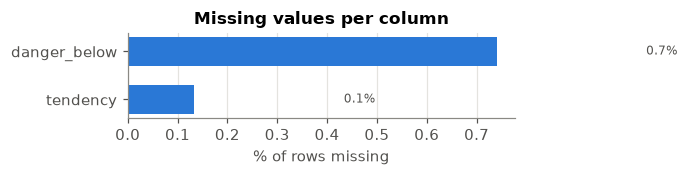

In [2]:
missing = data.isna().mean().sort_values()
missing = missing[missing > 0] * 100

fig, ax = plt.subplots(figsize=(7, 0.35 * len(missing) + 1))
ax.barh(missing.index, missing.values, color=BLUE, height=0.6)
for i, v in enumerate(missing.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column")
ax.grid(axis="y", visible=False)
plt.tight_layout()

## Target: danger level

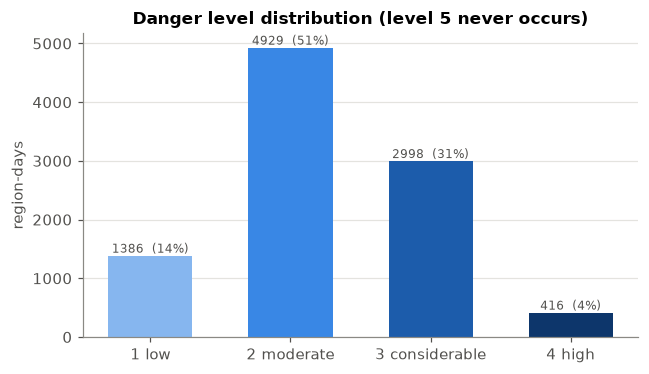

In [3]:
counts = data["danger_max"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([LEVEL_NAMES[l] for l in counts.index], counts.values,
       color=[LEVEL_COLORS[l] for l in counts.index], width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, f"{v}  ({v / counts.sum():.0%})", ha="center", fontsize=8, color="#52514e")
ax.set_ylabel("region-days")
ax.set_title("Danger level distribution (level 5 never occurs)")
ax.grid(axis="x", visible=False)
plt.tight_layout()

### Per region and per season

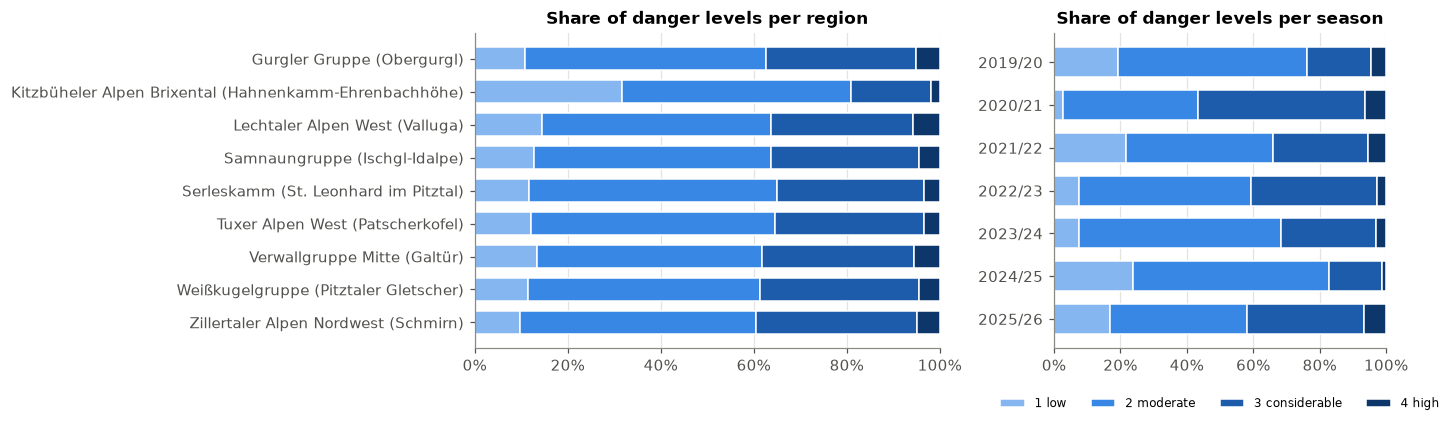

In [4]:
def stacked_share(ax, table, title):
    share = table.div(table.sum(axis=1), axis=0)
    left = np.zeros(len(share))
    for level in share.columns:
        ax.barh(share.index, share[level], left=left, color=LEVEL_COLORS[level],
                label=LEVEL_NAMES[level], height=0.7, edgecolor="white", linewidth=1)
        left += share[level].values
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.invert_yaxis()

by_region = pd.crosstab(data["region_name"] + " (" + data["station_name"] + ")", data["danger_max"])
by_season = pd.crosstab(data["season"], data["danger_max"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
stacked_share(axes[0], by_region, "Share of danger levels per region")
stacked_share(axes[1], by_season, "Share of danger levels per season")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=8)
plt.tight_layout()

### Over the course of a winter

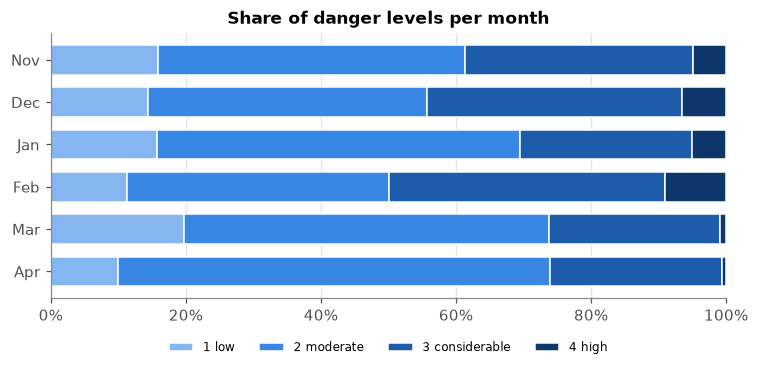

In [5]:
month_order = [11, 12, 1, 2, 3, 4]
month_labels = ["Nov", "Dec", "Jan", "Feb", "Mar", "Apr"]
by_month = pd.crosstab(data["month"], data["danger_max"]).reindex(month_order).fillna(0)
by_month.index = month_labels

fig, ax = plt.subplots(figsize=(7, 3.5))
stacked_share(ax, by_month, "Share of danger levels per month")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, frameon=False, fontsize=8)
plt.tight_layout()

### Danger level calendar
Every row is a region, every column a day. Shows how danger builds up and persists over a winter.

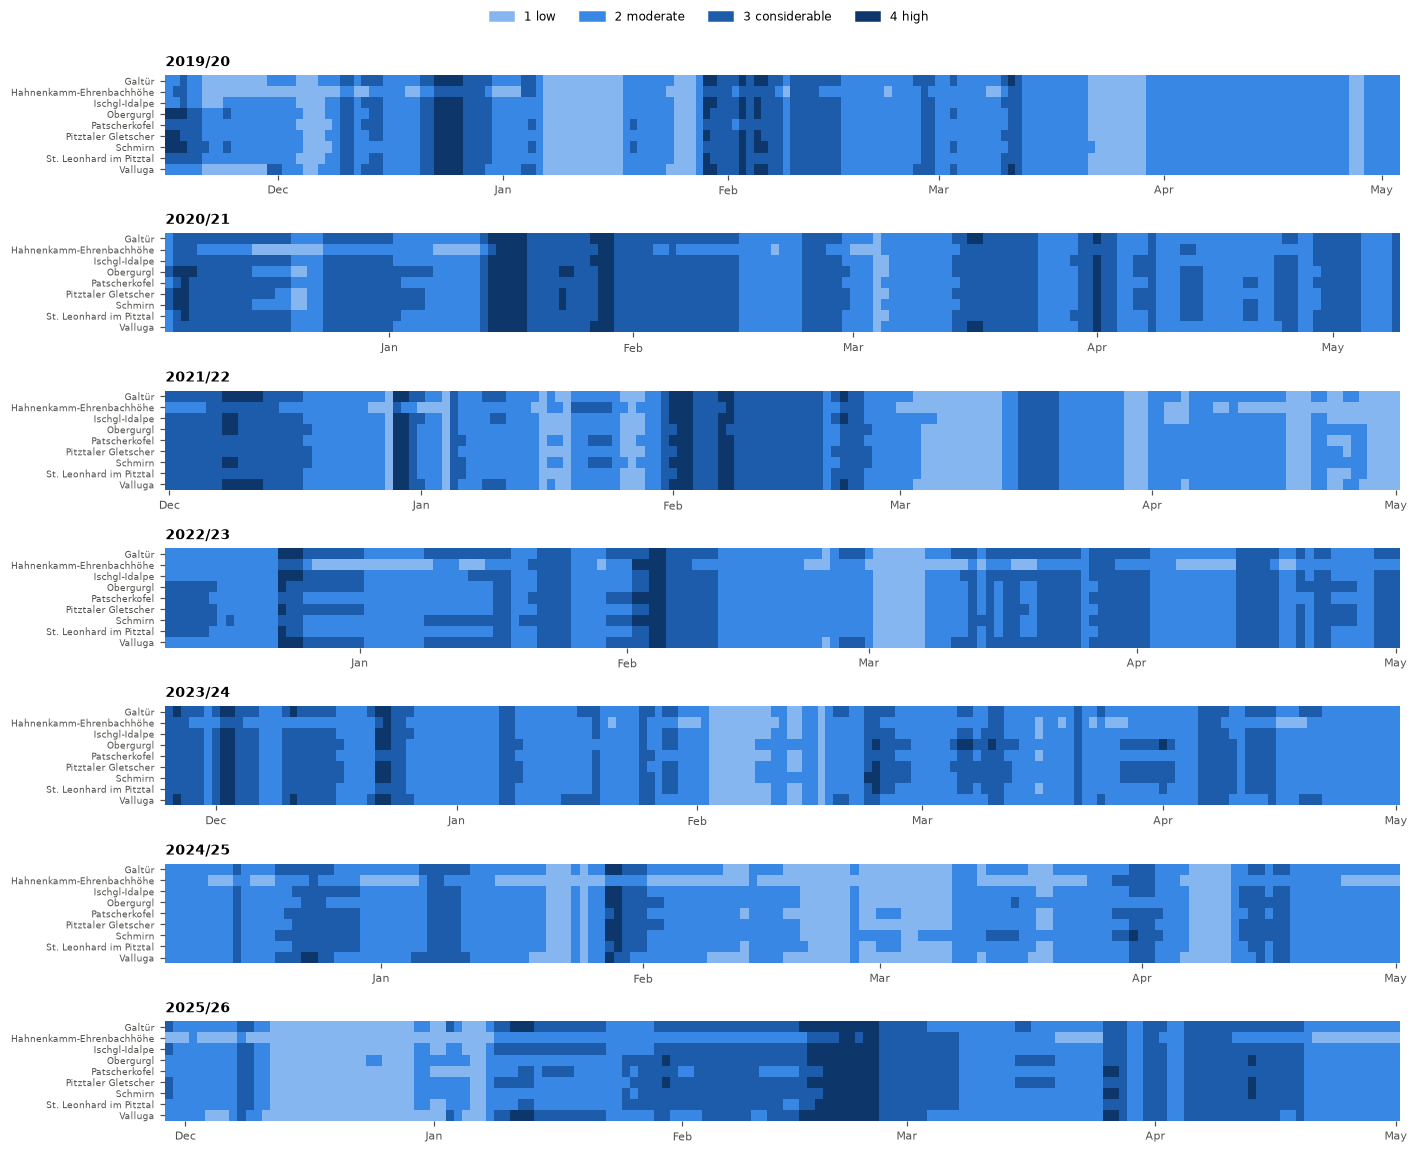

In [6]:
from matplotlib.colors import ListedColormap, BoundaryNorm

cmap = ListedColormap([LEVEL_COLORS[l] for l in [1, 2, 3, 4]])
cmap.set_bad("#f0efec")  # no bulletin
norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5, 4.5], cmap.N)

seasons = sorted(data["season"].unique())
fig, axes = plt.subplots(len(seasons), 1, figsize=(13, 1.5 * len(seasons)), sharex=False)
for ax, season in zip(axes, seasons):
    s = data[data["season"] == season]
    grid = s.pivot(index="station_name", columns="date", values="danger_max")
    grid = grid.reindex(columns=pd.date_range(grid.columns.min(), grid.columns.max()))
    ax.imshow(grid.values, aspect="auto", cmap=cmap, norm=norm, interpolation="nearest")
    ax.set_yticks(range(len(grid.index)), grid.index, fontsize=6)
    months = [i for i, d in enumerate(grid.columns) if d.day == 1]
    ax.set_xticks(months, [grid.columns[i].strftime("%b") for i in months], fontsize=7)
    ax.set_title(season, loc="left", fontsize=9)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=LEVEL_COLORS[l]) for l in [1, 2, 3, 4]]
fig.legend(handles, LEVEL_NAMES.values(), loc="upper center", ncol=4, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.97))

## Avalanche problems

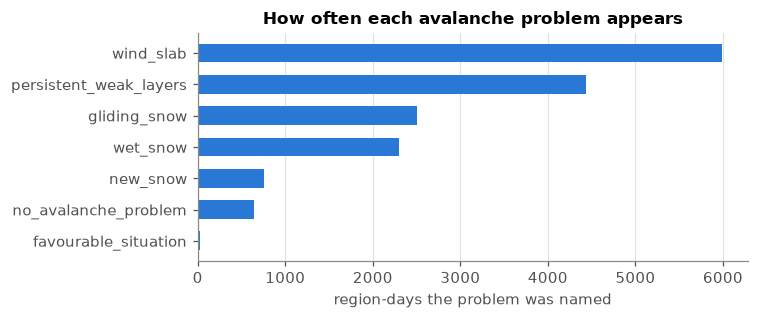

In [7]:
problems = data["problems"].str.split(";").explode().value_counts()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(problems.index, problems.values, color=BLUE, height=0.6)
ax.invert_yaxis()
ax.set_xlabel("region-days the problem was named")
ax.set_title("How often each avalanche problem appears")
ax.grid(axis="y", visible=False)
plt.tight_layout()

## Weather features

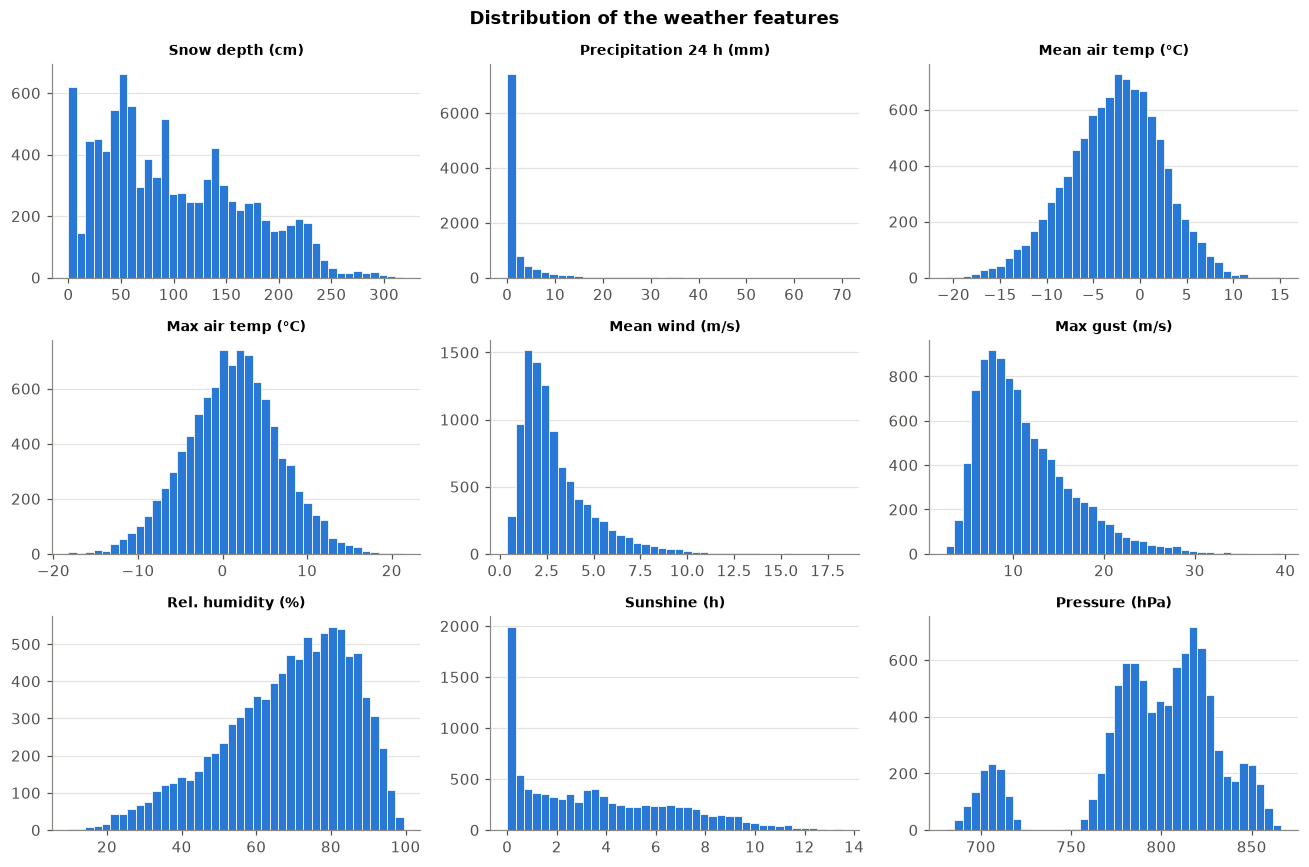

In [8]:
FEATURES = {
    "snow_depth_cm": "Snow depth (cm)",
    "precip_sum_mm": "Precipitation 24 h (mm)",
    "air_temp_mean": "Mean air temp (°C)",
    "air_temp_max": "Max air temp (°C)",
    "wind_speed_mean": "Mean wind (m/s)",
    "wind_gust_max": "Max gust (m/s)",
    "rel_humidity_mean": "Rel. humidity (%)",
    "sunshine_sum": "Sunshine (h)",
    "pressure_mean": "Pressure (hPa)",
}

fig, axes = plt.subplots(3, 3, figsize=(12, 8))
for ax, (col, label) in zip(axes.flat, FEATURES.items()):
    ax.hist(data[col].dropna(), bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(label, fontsize=9)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of the weather features", fontweight="bold")
plt.tight_layout()

Pressure is mostly a function of station elevation (each region uses a different station), so its histogram shows one bump per station rather than weather.

### Snow depth over time

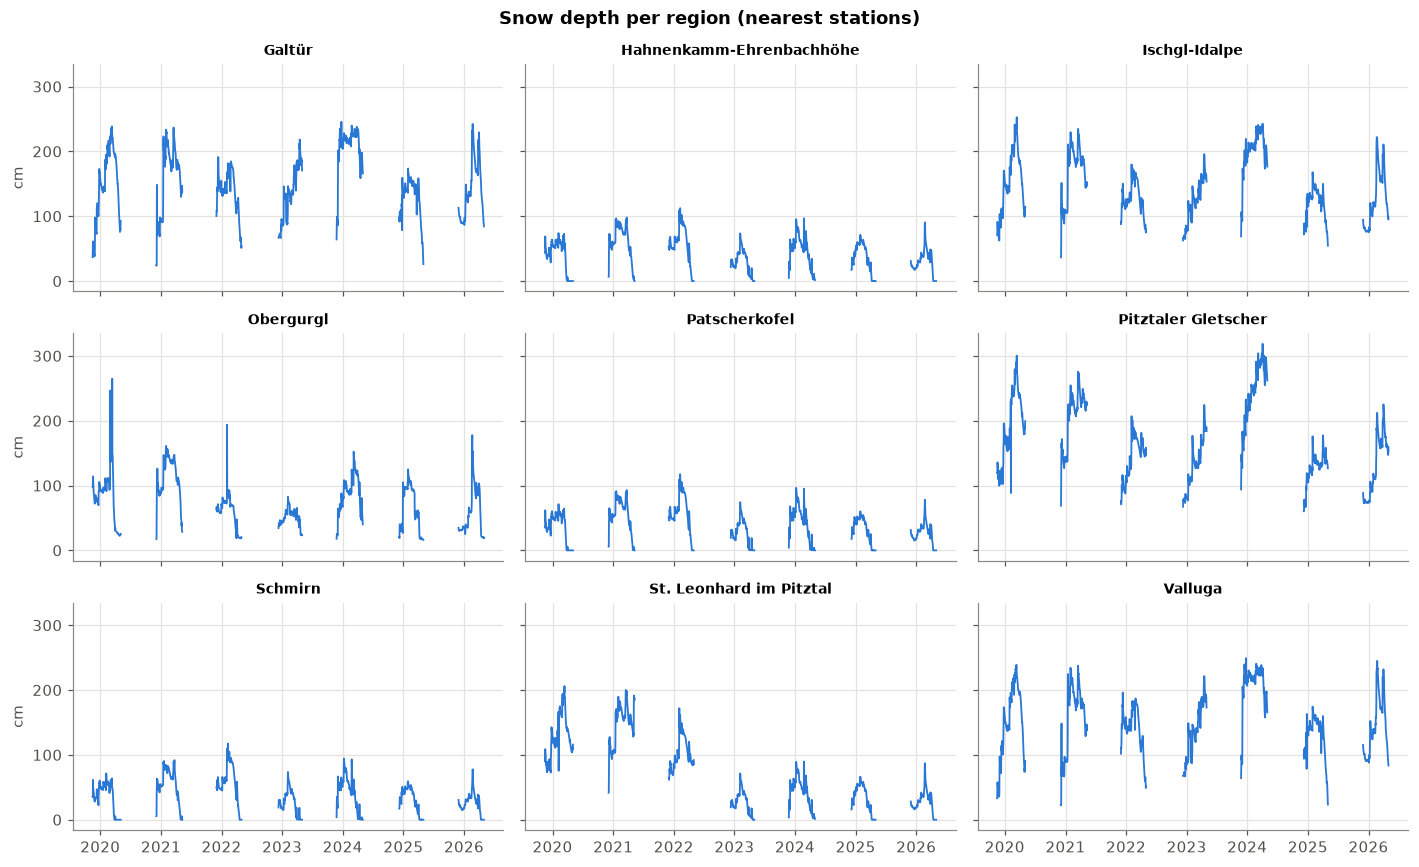

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True, sharey=True)
for ax, (station, s) in zip(axes.flat, data.groupby("station_name")):
    s = s.set_index("date")["snow_depth_cm"].asfreq("D")  # gaps between winters stay empty
    ax.plot(s.index, s.values, color=BLUE, linewidth=1.2)
    ax.set_title(station, fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("cm")
fig.suptitle("Snow depth per region (nearest stations)", fontweight="bold")
plt.tight_layout()

## Weather vs. danger level
Do the features actually separate the danger levels? Boxes show the middle 50 %, the line the median.

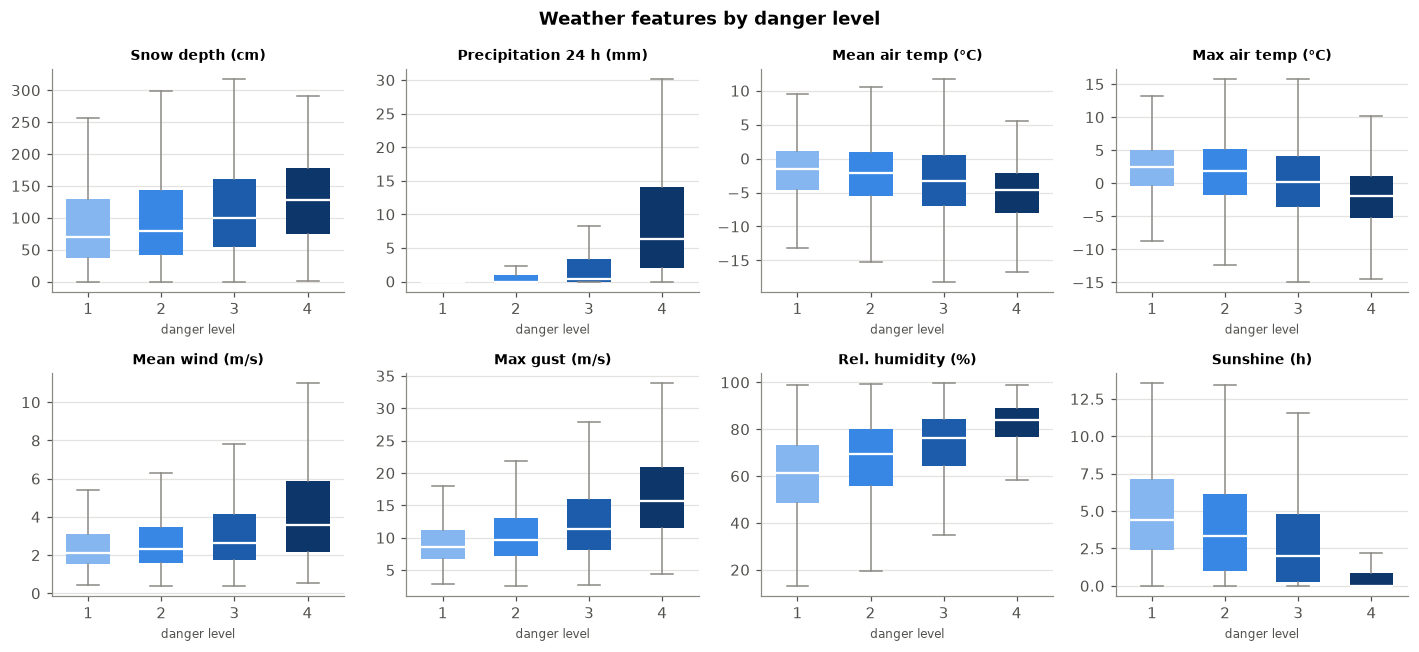

In [10]:
levels = [1, 2, 3, 4]

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, col in zip(axes.flat, ["snow_depth_cm", "precip_sum_mm", "air_temp_mean", "air_temp_max",
                               "wind_speed_mean", "wind_gust_max", "rel_humidity_mean", "sunshine_sum"]):
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in levels]
    bp = ax.boxplot(groups, tick_labels=levels, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": "#8a8984"}, capprops={"color": "#8a8984"})
    for patch, l in zip(bp["boxes"], levels):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(FEATURES[col], fontsize=9)
    ax.set_xlabel("danger level", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Weather features by danger level", fontweight="bold")
plt.tight_layout()

### Fresh snow: precipitation over the last days

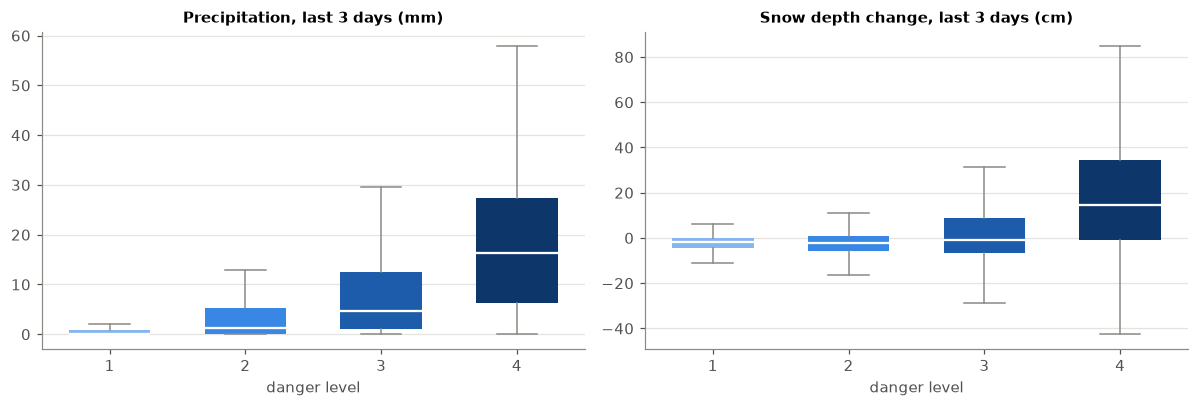

In [11]:
# 3-day precipitation sum and 3-day snow depth change per region (the bulletin is about loading over several days)
data = data.sort_values(["region", "date"])
g = data.groupby("region")
data["precip_3d"] = g["precip_sum_mm"].transform(lambda x: x.rolling(3, min_periods=2).sum())
data["snow_change_3d"] = g["snow_depth_cm"].diff(3)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, label in [(axes[0], "precip_3d", "Precipitation, last 3 days (mm)"),
                       (axes[1], "snow_change_3d", "Snow depth change, last 3 days (cm)")]:
    groups = [data.loc[data["danger_max"] == l, col].dropna() for l in levels]
    bp = ax.boxplot(groups, tick_labels=levels, widths=0.6, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "linewidth": 1.5},
                    whiskerprops={"color": "#8a8984"}, capprops={"color": "#8a8984"})
    for patch, l in zip(bp["boxes"], levels):
        patch.set(facecolor=LEVEL_COLORS[l], edgecolor="none")
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("danger level")
    ax.grid(axis="x", visible=False)
plt.tight_layout()

### Correlation with the danger level

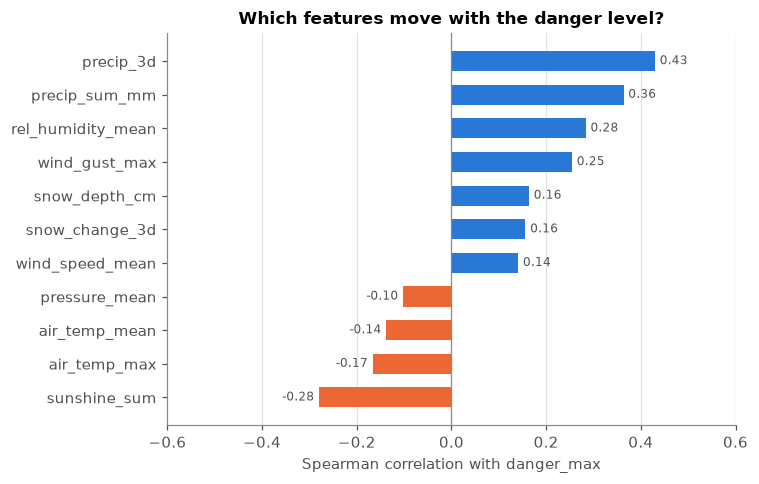

In [12]:
num_cols = list(FEATURES) + ["precip_3d", "snow_change_3d"]
# Spearman = Pearson on ranks (avoids needing scipy)
corr = data[num_cols].rank().corrwith(data["danger_max"].rank()).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(corr.index, corr.values, color=[BLUE if v > 0 else ORANGE for v in corr.values], height=0.6)
ax.axvline(0, color="#8a8984", linewidth=0.8)
for i, v in enumerate(corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color="#52514e")
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("Spearman correlation with danger_max")
ax.set_title("Which features move with the danger level?")
ax.grid(axis="y", visible=False)
plt.tight_layout()

### Correlation between the features

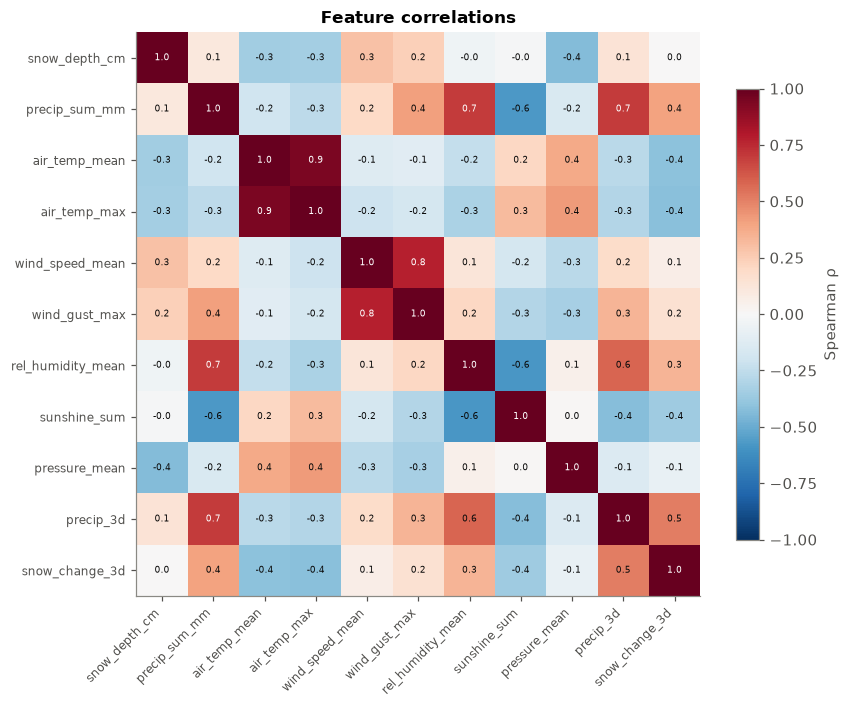

In [13]:
c = data[num_cols].rank().corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(c)), c.columns, fontsize=8)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6,
                color="white" if abs(c.iloc[i, j]) > 0.6 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Feature correlations")
plt.tight_layout()

## Persistence: how often does the level change from one day to the next?

level unchanged from previous day: 79.2%


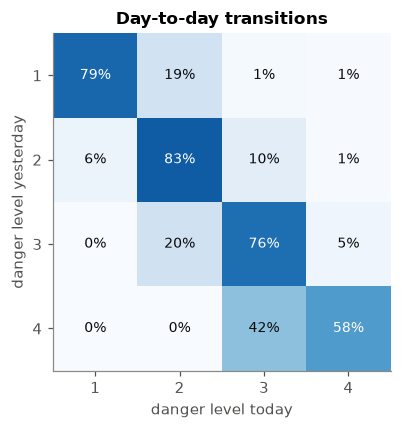

In [14]:
data["prev_danger"] = data.groupby("region")["danger_max"].shift(1)
consecutive = data["date"] - data.groupby("region")["date"].shift(1) == pd.Timedelta(days=1)
trans = pd.crosstab(data.loc[consecutive, "prev_danger"], data.loc[consecutive, "danger_max"], normalize="index")

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(trans, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4), [int(c) for c in trans.columns])
ax.set_yticks(range(4), [int(i) for i in trans.index])
for i in range(4):
    for j in range(4):
        v = trans.iloc[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.5 else "#0b0b0b")
ax.set_xlabel("danger level today")
ax.set_ylabel("danger level yesterday")
ax.set_title("Day-to-day transitions")
ax.grid(False)
plt.tight_layout()

print(f"level unchanged from previous day: {(data.loc[consecutive, 'prev_danger'] == data.loc[consecutive, 'danger_max']).mean():.1%}")

That share is roughly the accuracy of the "persistence" baseline (predict yesterday's level). A model has to beat it to be useful.